── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.0     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


[1] "画图完成！纵坐标已统一。"


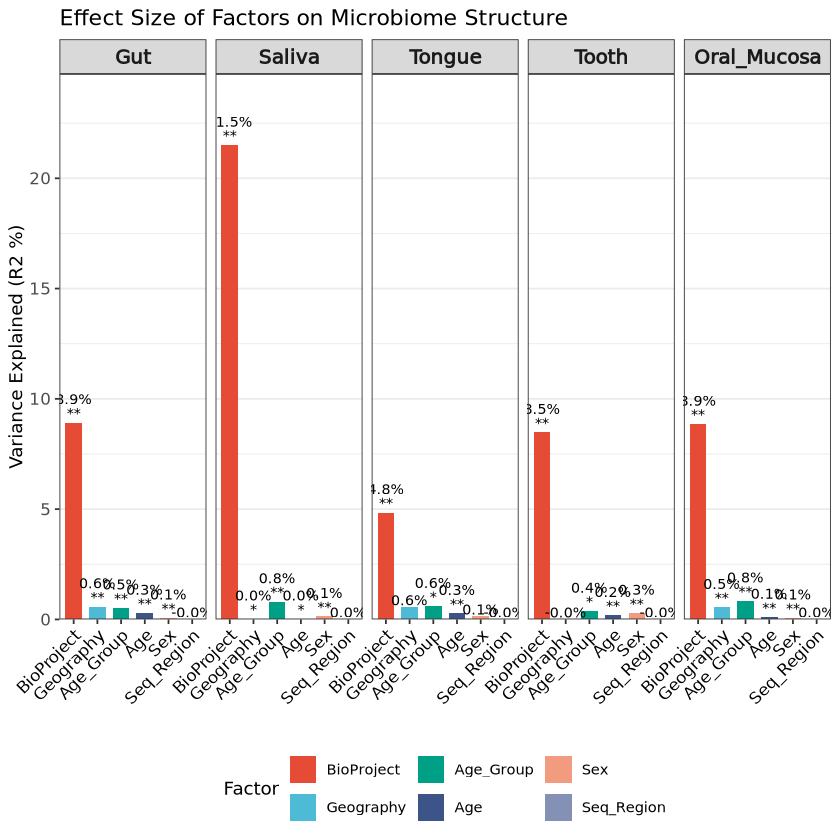

In [1]:
# 加载必要的包
library(tidyverse)
library(ggplot2)
library(ggsci) 

# ==========================================================
# 1. 设置路径与读取数据
# ==========================================================
base_path <- "/home/hexincheng/task/huang_teacher/gut_adonis_analysis_0115/oral_gut_0127"

files_to_read <- list(
  Gut = file.path(base_path, "gut/adonis_gut_result_0127.csv"),
  Saliva = file.path(base_path, "oral/adonis_result_Saliva_0127.csv"),
  Oral_Mucosa = file.path(base_path, "oral/adonis_result_Oral_Mucosa_0127.csv"),
  Tongue = file.path(base_path, "oral/adonis_result_Tongue_0127.csv"),
  Tooth = file.path(base_path, "oral/adonis_result_Tooth_0127.csv")
)

all_data <- list()

for (site_name in names(files_to_read)) {
  fpath <- files_to_read[[site_name]]
  if (file.exists(fpath)) {
    df <- read.csv(fpath)
    df_clean <- df %>%
      rename(Term = X) %>%
      filter(!Term %in% c("Residual", "Total")) %>%
      mutate(Site = site_name) %>%
      select(Site, Term, R2, matches("Pr|P.value"))
    
    colnames(df_clean)[4] <- "P_value"
    all_data[[site_name]] <- df_clean
  }
}

plot_data <- bind_rows(all_data)

# ==========================================================
# 2. 数据处理：构建标签
# ==========================================================
plot_data <- plot_data %>%
  mutate(
    Significance = case_when(
      P_value < 0.001 ~ "***",
      P_value < 0.01 ~ "**",
      P_value < 0.05 ~ "*",
      TRUE ~ ""
    ),
    R2_Percent = R2 * 100,
    Label_Text = paste0(sprintf("%.1f", R2_Percent), "%", 
                        ifelse(Significance == "", "", paste0("\n", Significance)))
  )

# 设置因子顺序
term_levels <- c("BioProject", "Geography", "Age_Group", "Age", "Sex", "Seq_Region")
plot_data$Term <- factor(plot_data$Term, levels = term_levels)

site_levels <- c("Gut", "Saliva", "Tongue", "Tooth", "Oral_Mucosa")
plot_data$Site <- factor(plot_data$Site, levels = site_levels)

# ==========================================================
# 3. 绘图 (统一纵坐标版)
# ==========================================================
p <- ggplot(plot_data, aes(x = Term, y = R2_Percent, fill = Term)) +
  # 柱状图
  geom_bar(stat = "identity", position = position_dodge(width = 0.8), width = 0.7) +
  
  # 【关键修改】改为固定坐标轴 (scales = "fixed")
  # 这样所有子图都使用同一个 Y 轴范围
  facet_wrap(~Site, scales = "fixed", nrow = 1) +
  
  # 标签
  geom_text(aes(label = Label_Text), 
            vjust = -0.2, 
            size = 3, 
            lineheight = 0.8) +
  
  # 扩展 Y 轴
  scale_y_continuous(expand = expansion(mult = c(0, 0.15))) +
  
  # 颜色与主题
  scale_fill_npg() +
  theme_bw() +
  
  labs(
    title = "Effect Size of Factors on Microbiome Structure",
    y = "Variance Explained (R2 %)",
    x = "",
    fill = "Factor"
  ) +
  
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1, size = 10, color = "black"),
    axis.text.y = element_text(size = 10),
    strip.text = element_text(size = 12, face = "bold"),
    legend.position = "bottom",
    panel.grid.major.x = element_blank()
  )

# ==========================================================
# 4. 保存图片
# ==========================================================
ggsave(file.path(base_path, "Adonis_Result_Unified.png"), p, width = 14, height = 7, dpi = 300)
# ggsave(file.path(base_path, "Adonis_Result_Unified.pdf"), p, width = 14, height = 7)

print(p)
print("画图完成！纵坐标已统一。")